In [1]:
import os

module4_folder = "../data/processed/module4"

if os.path.exists(module4_folder):
    print("Module 4 folder found!")

    files = os.listdir(module4_folder)

    print("\nFiles available in Module 4:")
    for file in files:
        print(file)
else:
    print("Module 4 folder not found. Check your project path.")

Module 4 folder found!

Files available in Module 4:
duplicate_investigation_report.csv
headway_missing_values_report.csv
headway_quality_report.csv
hyderabad_trip_duration_quality_report.csv
iqr_outlier_summary.csv
MODULE4_ASSUMPTIONS_AND_LIMITATIONS.md
outlier_verification_report.csv
route_features_scaled.csv
route_missing_values_report.csv
route_missing_values_summary.csv


In [1]:
import pandas as pd
import os

file_path = "../data/processed/module4/route_features_scaled.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("SUCCESS: Module 4 dataset loaded!")
    print("Number of rows and columns:", df.shape)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum())
else:
    print("route_features_scaled.csv not found!")

SUCCESS: Module 4 dataset loaded!
Number of rows and columns: (9338, 8)

First 5 rows:


,trip_count,distinct_stop_count,average_stops_per_trip,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune
0,-0.397566,-0.210807,-0.618302,1,0,0,0,0
1,-0.397566,-1.216965,-1.579736,1,0,0,0,0
2,-0.383906,-0.122029,-0.571172,1,0,0,0,0
3,-0.370245,-0.122029,-0.561747,1,0,0,0,0
4,-0.383906,-0.299586,-0.759689,1,0,0,0,0



Column names:
['trip_count', 'distinct_stop_count', 'average_stops_per_trip', 'city_Bangalore', 'city_Delhi', 'city_Hyderabad', 'city_Mumbai', 'city_Pune']

Missing values:
trip_count                0
distinct_stop_count       0
average_stops_per_trip    0
city_Bangalore            0
city_Delhi                0
city_Hyderabad            0
city_Mumbai               0
city_Pune                 0
dtype: int64


Step 2: Prepare features for Machine Learning
For our first model, K-Means Clustering, we will use the three scaled numerical features.

We will keep the city columns separately so that we can understand which cities the clusters belong to.

In [2]:
# Select numerical features for clustering

cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Selected features:")
print(cluster_features)

print("\nFeature matrix shape:")
print(X.shape)

print("\nFirst 5 records:")
display(X.head())

print("\nChecking missing values:")
print(X.isnull().sum())

Selected features:
['trip_count', 'distinct_stop_count', 'average_stops_per_trip']

Feature matrix shape:
(9338, 3)

First 5 records:


,trip_count,distinct_stop_count,average_stops_per_trip
0,-0.397566,-0.210807,-0.618302
1,-0.397566,-1.216965,-1.579736
2,-0.383906,-0.122029,-0.571172
3,-0.370245,-0.122029,-0.561747
4,-0.383906,-0.299586,-0.759689



Checking missing values:
trip_count                0
distinct_stop_count       0
average_stops_per_trip    0
dtype: int64


Step 3: Check city distribution

In [3]:
city_columns = [
    'city_Bangalore',
    'city_Delhi',
    'city_Hyderabad',
    'city_Mumbai',
    'city_Pune'
]

city_counts = df[city_columns].sum()

print("Number of route records in each city:")
display(city_counts)

Number of route records in each city:


city_Bangalore    4416
city_Delhi        2964
city_Hyderabad    1031
city_Mumbai        612
city_Pune          315
dtype: int64

Step 4: Elbow Method
Purpose: The Elbow Method helps us choose a suitable number of clusters (K) for K-Means.

It calculates the Within-Cluster Sum of Squares (WCSS), also called inertia, for different K values. We look for the point where the decrease starts slowing down.

In [7]:
import os

print("Current location:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current location:
c:\Users\nagar\Downloads\routeranker-upload\notebooks

Files and folders:
['module1_data_collection.ipynb', 'Module2_Feature_Engineering_All_Cities.ipynb', 'Module3_Exploratory_Data_Analysis.ipynb', 'Module4_Data_Preprocessing.ipynb', 'Module5_ML_Model_Development.ipynb']


In [8]:
import os

possible_paths = [
    "../data/processed/module4/route_features_scaled.csv",
    "data/processed/module4/route_features_scaled.csv"
]

for path in possible_paths:
    print(path, ":", os.path.exists(path))

../data/processed/module4/route_features_scaled.csv : True
data/processed/module4/route_features_scaled.csv : False


In [9]:
import pandas as pd

df = pd.read_csv("../data/processed/module4/route_features_scaled.csv")

cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Dataset loaded:", X.shape)

Dataset loaded: (9338, 3)


In [11]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 5.1 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.4 MB 6.7 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.4 MB 8.3 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.4 MB 7.7 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.4 MB 7.6 MB/s eta 0:00:01
   ------------------------------------- -- 7.9/8.4 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 6.7 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/37.4 MB 5.2 MB/s eta 0:00:07
   -- ------------------------------------- 2.6/37.4 MB 6.2 MB/s eta 0:00:06
   ---- ----------------------------------- 3.9/37.4 MB 6.3 MB/s eta 0:00:06
   ----- ---------------------------------- 5.5/37.4 MB 6.5 MB/s eta 0:00:05
   ------- -------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn installed successfully!")

Scikit-learn version: 1.9.1
Scikit-learn installed successfully!


Step 4: Elbow Method.
Import the required libraries

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


Prepare the feature matrix
If X is already available, you can skip this cell.

In [14]:
cluster_features = [
    'trip_count',
    'distinct_stop_count',
    'average_stops_per_trip'
]

X = df[cluster_features]

print("Feature matrix:", X.shape)

Feature matrix: (9338, 3)


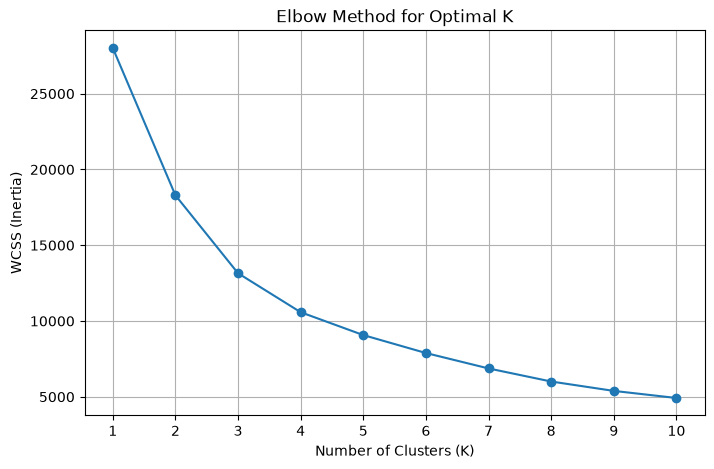

In [15]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Apply K-Means clustering

In [16]:
from sklearn.cluster import KMeans

# Select the number of clusters based on your Elbow graph
BEST_K = 3

# Create K-Means model
kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

# Train the model
kmeans_labels = kmeans.fit_predict(X)

# Add cluster labels to the dataset
df['kmeans_cluster'] = kmeans_labels

print("K-Means clustering completed!")
print("\nCluster distribution:")
print(df['kmeans_cluster'].value_counts().sort_index())

K-Means clustering completed!

Cluster distribution:
kmeans_cluster
0    4420
1    4657
2     261
Name: count, dtype: int64


Evaluate K-Means clustering

In [17]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette = silhouette_score(X, kmeans_labels)
db_index = davies_bouldin_score(X, kmeans_labels)

print("K-Means Clustering Evaluation")
print("--------------------------------")
print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", db_index)

K-Means Clustering Evaluation
--------------------------------
Silhouette Score: 0.42159947305517503
Davies-Bouldin Index: 0.8485941453975121


Analyze cluster profiles


In [18]:
cluster_profile = df.groupby('kmeans_cluster')[cluster_features].mean()

print("K-Means Cluster Profile:")
display(cluster_profile)

K-Means Cluster Profile:


,trip_count,distinct_stop_count,average_stops_per_trip
kmeans_cluster,,,
0,-0.101155,0.634538,0.815210
1,-0.153851,-0.648670,-0.749431
2,4.458191,0.828345,-0.433440


Save the clustering results

In [19]:
import os

output_folder = "../data/processed/module5"
os.makedirs(output_folder, exist_ok=True)

df.to_csv(
    os.path.join(output_folder, "module5_route_features_with_clusters.csv"),
    index=False
)

cluster_profile.to_csv(
    os.path.join(output_folder, "kmeans_cluster_profile.csv")
)

print("K-Means output files saved successfully!")

K-Means output files saved successfully!


Step 6: DBSCAN Clustering
Now we will implement DBSCAN (Density-Based Spatial Clustering of Applications with Noise).

Unlike K-Means, DBSCAN does not require us to specify the number of clusters in advance. It groups nearby data points and identifies isolated points as noise (-1).
 

import DBSCAN

In [20]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import numpy as np

print("DBSCAN libraries imported successfully!")

DBSCAN libraries imported successfully!


Step 6.2: Find suitable DBSCAN parameters
We will test different values of eps and min_samples.

In [21]:
results = []

for eps in [0.3, 0.5, 0.7, 1.0]:
    for min_samples in [5, 10]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        # Exclude noise points for cluster evaluation
        mask = labels != -1
        valid_labels = labels[mask]
        n_clusters = len(set(valid_labels))
        noise_count = np.sum(labels == -1)

        silhouette = np.nan
        db_index = np.nan

        if n_clusters >= 2 and mask.sum() > n_clusters:
            silhouette = silhouette_score(X[mask], valid_labels)
            db_index = davies_bouldin_score(X[mask], valid_labels)

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_points": noise_count,
            "noise_percentage": round(noise_count / len(X) * 100, 2),
            "silhouette_score": silhouette,
            "davies_bouldin_index": db_index
        })

dbscan_results = pd.DataFrame(results)

display(dbscan_results)

,eps,min_samples,clusters,noise_points,noise_percentage,silhouette_score,davies_bouldin_index
0,0.3,5,7,277,2.97,0.152358,0.567100
1,0.3,10,2,457,4.89,0.442812,0.530550
2,0.5,5,6,137,1.47,0.435633,0.494642
3,0.5,10,2,197,2.11,0.714516,0.260203
4,0.7,5,1,83,0.89,NaN,NaN
5,0.7,10,2,126,1.35,0.734108,0.305272
6,1.0,5,1,39,0.42,NaN,NaN
7,1.0,10,1,55,0.59,NaN,NaN


Step 6.3: Select the best valid parameters

In [22]:
valid_results = dbscan_results.dropna(subset=["silhouette_score"])

if not valid_results.empty:
    best_row = valid_results.sort_values(
        by="silhouette_score",
        ascending=False
    ).iloc[0]

    BEST_EPS = float(best_row["eps"])
    BEST_MIN_SAMPLES = int(best_row["min_samples"])

    print("Selected eps:", BEST_EPS)
    print("Selected min_samples:", BEST_MIN_SAMPLES)
else:
    BEST_EPS = 0.5
    BEST_MIN_SAMPLES = 10

    print("No parameter combination produced at least two valid clusters.")
    print("Using initial parameters for further investigation.")

Selected eps: 0.7
Selected min_samples: 10


Step 6.4: Apply DBSCAN

In [24]:
dbscan = DBSCAN(
    eps=BEST_EPS,
    min_samples=BEST_MIN_SAMPLES
)

dbscan_labels = dbscan.fit_predict(X)

df["dbscan_cluster"] = dbscan_labels

print("DBSCAN clustering completed!")

print("\nDBSCAN cluster distribution:")
print(df["dbscan_cluster"].value_counts().sort_index())

print("\nNumber of noise points:")
print((dbscan_labels == -1).sum())

DBSCAN clustering completed!

DBSCAN cluster distribution:
dbscan_cluster
-1     126
 0    9182
 1      30
Name: count, dtype: int64

Number of noise points:
126


Step 6.5: Save DBSCAN results

In [25]:
import os

output_folder = "../data/processed/module5"
os.makedirs(output_folder, exist_ok=True)

df.to_csv(
    os.path.join(output_folder, "module5_route_features_with_clusters.csv"),
    index=False
)

dbscan_results.to_csv(
    os.path.join(output_folder, "dbscan_parameter_comparison.csv"),
    index=False
)

noise_points = df[df["dbscan_cluster"] == -1]

noise_points.to_csv(
    os.path.join(output_folder, "dbscan_noise_points.csv"),
    index=False
)

print("DBSCAN output files saved successfully!")

DBSCAN output files saved successfully!


Evaluate DBSCAN

In [26]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

labels = df["dbscan_cluster"].values

# Remove noise points for cluster evaluation
mask = labels != -1

valid_labels = labels[mask]
X_valid = X.iloc[np.where(mask)[0]]

n_clusters = len(set(valid_labels))
noise_count = np.sum(labels == -1)

print("DBSCAN Evaluation")
print("--------------------------")
print("Number of clusters:", n_clusters)
print("Number of noise points:", noise_count)
print("Noise percentage:", round(noise_count / len(labels) * 100, 2), "%")

if n_clusters >= 2 and len(X_valid) > n_clusters:
    silhouette = silhouette_score(X_valid, valid_labels)
    db_index = davies_bouldin_score(X_valid, valid_labels)

    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", db_index)
else:
    print("Not enough clusters to calculate clustering scores.")

DBSCAN Evaluation
--------------------------
Number of clusters: 2
Number of noise points: 126
Noise percentage: 1.35 %
Silhouette Score: 0.7341082144878736
Davies-Bouldin Index: 0.3052720363849467


Analyze noise points

In [27]:
noise_points = df[df["dbscan_cluster"] == -1]

print("Total noise points:", len(noise_points))

print("\nFirst 10 noise records:")
display(noise_points.head(10))

print("\nNoise point feature summary:")
display(noise_points[cluster_features].describe())

Total noise points: 126

First 10 noise records:


,trip_count,distinct_stop_count,average_stops_per_trip,city_Bangalore,city_Delhi,city_Hyderabad,city_Mumbai,city_Pune,kmeans_cluster,dbscan_cluster
2792,3.919151,1.979065,1.445954,1,0,0,0,0,2,-1
4344,2.758008,2.866851,2.407388,1,0,0,0,0,2,-1
6808,-0.028733,3.577080,7.723553,0,1,0,0,0,0,-1
7275,0.886521,3.577080,7.723553,0,1,0,0,0,0,-1
7380,3.741564,2.541330,-1.003339,0,0,1,0,0,2,-1
7403,5.039311,3.902602,-0.752902,0,0,1,0,0,2,-1
7417,1.009465,2.926037,0.176969,0,0,1,0,0,0,-1
7418,2.225249,3.547487,-0.247779,0,0,1,0,0,2,-1
7420,1.747132,2.452551,0.295648,0,0,1,0,0,0,-1
7423,15.434949,6.565960,-0.258586,0,0,1,0,0,2,-1



Noise point feature summary:


,trip_count,distinct_stop_count,average_stops_per_trip
count,126.000000,126.000000,126.000000
mean,4.325063,2.976298,0.143793
std,4.192089,3.036173,1.634417
min,-0.383906,-1.276151,-1.634787
25%,1.286090,1.246642,-0.667387
50%,3.297598,2.748480,-0.270174
75%,5.920413,4.072761,0.334194
max,28.084568,22.102216,7.723553


Visualize K-Means clusters and DBSCAN clusters using PCA
PCA reduces the three numerical features to two dimensions so that we can visualize them.

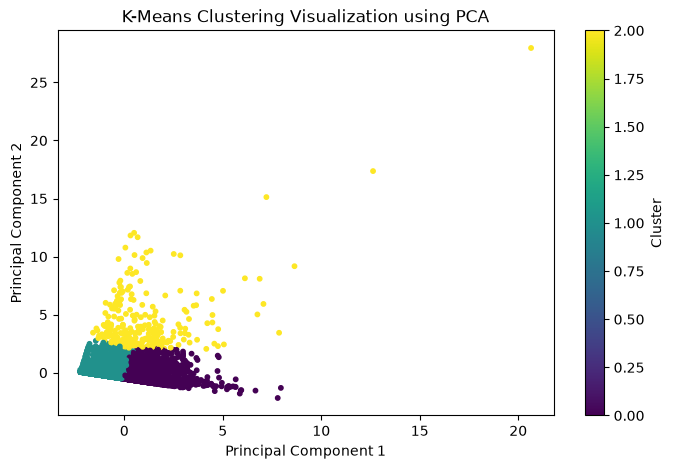

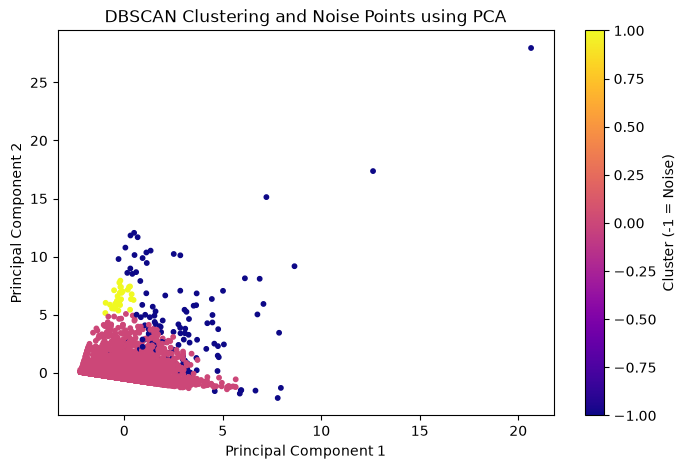

In [28]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# K-Means visualization
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["kmeans_cluster"],
    cmap="viridis",
    s=10
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

# DBSCAN visualization
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["dbscan_cluster"],
    cmap="plasma",
    s=10
)

plt.title("DBSCAN Clustering and Noise Points using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

Compare K-Means and DBSCAN

In [29]:
comparison = pd.DataFrame({
    "Model": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [
        len(set(df["kmeans_cluster"])),
        len(set(df["dbscan_cluster"]) - {-1})
    ],
    "Noise_Points": [
        0,
        int((df["dbscan_cluster"] == -1).sum())
    ]
})

display(comparison)

comparison.to_csv(
    "../data/processed/module5/clustering_model_comparison.csv",
    index=False
)

print("Clustering comparison saved successfully!")

,Model,Number_of_Clusters,Noise_Points
0,K-Means,3,0
1,DBSCAN,2,126


Clustering comparison saved successfully!


Step 8: Check classification readiness
Your current dataset has three numerical features and five city-encoding columns. It does not contain a genuine classification target such as a verified route category or service label.

We must not invent labels just to train a classifier.


In [30]:
# Check available columns for classification

print("Available dataset columns:")
print(df.columns.tolist())

possible_targets = [
    'route_category',
    'service_class',
    'frequency_class',
    'demand_class',
    'target',
    'label'
]

available_targets = [
    col for col in possible_targets
    if col in df.columns
]

if available_targets:
    print("\nPossible target columns:", available_targets)
else:
    print("\nNo genuine classification target found.")
    print("Random Forest and XGBoost classification will be skipped.")

Available dataset columns:
['trip_count', 'distinct_stop_count', 'average_stops_per_trip', 'city_Bangalore', 'city_Delhi', 'city_Hyderabad', 'city_Mumbai', 'city_Pune', 'kmeans_cluster', 'dbscan_cluster']

No genuine classification target found.
Random Forest and XGBoost classification will be skipped.


Step 9: Save final Module 5 results
Now let's save your models, cluster profiles and evaluation results.

In [31]:
import joblib
import os

output_folder = "../data/processed/module5"
os.makedirs(output_folder, exist_ok=True)

joblib.dump(kmeans, os.path.join(output_folder, "kmeans_model.joblib"))
joblib.dump(dbscan, os.path.join(output_folder, "dbscan_model.joblib"))

print("K-Means and DBSCAN models saved successfully!")

K-Means and DBSCAN models saved successfully!


Save final evaluation summary

In [32]:
summary = pd.DataFrame([
    {
        "Model": "K-Means",
        "Clusters": 3,
        "Noise_Points": 0,
        "Silhouette_Score": 0.42159947305517503,
        "Davies_Bouldin_Index": 0.8485941453975121
    },
    {
        "Model": "DBSCAN",
        "Clusters": 2,
        "Noise_Points": 126,
        "Silhouette_Score": 0.7341082144878736,
        "Davies_Bouldin_Index": 0.3052720363849467
    }
])

display(summary)

summary.to_csv(
    os.path.join(output_folder, "module5_summary.csv"),
    index=False
)

print("Module 5 evaluation summary saved!")

,Model,Clusters,Noise_Points,Silhouette_Score,Davies_Bouldin_Index
0,K-Means,3,0,0.421599,0.848594
1,DBSCAN,2,126,0.734108,0.305272


Module 5 evaluation summary saved!


Step 10: Check your final output folder

In [33]:
print("MODULE 5 OUTPUT FILES")

for file in sorted(os.listdir(output_folder)):
    print("✓", file)

MODULE 5 OUTPUT FILES
✓ clustering_model_comparison.csv
✓ dbscan_model.joblib
✓ dbscan_noise_points.csv
✓ dbscan_parameter_comparison.csv
✓ kmeans_cluster_profile.csv
✓ kmeans_model.joblib
✓ module5_route_features_with_clusters.csv
✓ module5_summary.csv


 Verify all Module 5 deliverables

In [34]:
import os

folders = [
    "../data/processed/module5",
    "../reports/module5"
]

for folder in folders:
    print("\nFolder:", folder)

    if os.path.exists(folder):
        for file in sorted(os.listdir(folder)):
            print("  ✓", file)
    else:
        print("Folder not found!")


Folder: ../data/processed/module5
  ✓ clustering_model_comparison.csv
  ✓ dbscan_model.joblib
  ✓ dbscan_noise_points.csv
  ✓ dbscan_parameter_comparison.csv
  ✓ kmeans_cluster_profile.csv
  ✓ kmeans_model.joblib
  ✓ module5_route_features_with_clusters.csv
  ✓ module5_summary.csv

Folder: ../reports/module5
Folder not found!


Verify Module 5 files

In [35]:
import os

folders = {
    "Module 5 Processed Data": "../data/processed/module5",
    "Module 5 Reports": "../reports/module5"
}

for folder_name, folder_path in folders.items():

    print("\n" + "=" * 45)
    print(folder_name)
    print("=" * 45)

    if os.path.exists(folder_path):
        files = os.listdir(folder_path)

        if files:
            for file in sorted(files):
                print("SUCCESS:", file)
        else:
            print("Folder is empty!")
    else:
        print("Folder not found:", folder_path)


Module 5 Processed Data
SUCCESS: clustering_model_comparison.csv
SUCCESS: dbscan_model.joblib
SUCCESS: dbscan_noise_points.csv
SUCCESS: dbscan_parameter_comparison.csv
SUCCESS: kmeans_cluster_profile.csv
SUCCESS: kmeans_model.joblib
SUCCESS: module5_route_features_with_clusters.csv
SUCCESS: module5_summary.csv

Module 5 Reports
Folder not found: ../reports/module5


In [36]:
import joblib
import os

model_folder = "../data/processed/module5"

kmeans_model = joblib.load(
    os.path.join(model_folder, "kmeans_model.joblib")
)

dbscan_model = joblib.load(
    os.path.join(model_folder, "dbscan_model.joblib")
)

print("K-Means model loaded successfully!")
print("DBSCAN model loaded successfully!")

print("K-Means model:", type(kmeans_model))
print("DBSCAN model:", type(dbscan_model))

K-Means model loaded successfully!
DBSCAN model loaded successfully!
K-Means model: <class 'sklearn.cluster._kmeans.KMeans'>
DBSCAN model: <class 'sklearn.cluster._dbscan.DBSCAN'>


In [38]:
import os

folders = [
    "../data/processed/module5",
    "../reports/module5"
]

for folder in folders:
    print("\nFolder:", folder)

    if os.path.exists(folder):
        files = os.listdir(folder)

        for file in files:
            print("  ✔", file)

        if not files:
            print("  Folder is empty")
    else:
        print("  Folder not found")


Folder: ../data/processed/module5
  ✔ clustering_model_comparison.csv
  ✔ dbscan_model.joblib
  ✔ dbscan_noise_points.csv
  ✔ dbscan_parameter_comparison.csv
  ✔ kmeans_cluster_profile.csv
  ✔ kmeans_model.joblib
  ✔ module5_route_features_with_clusters.csv
  ✔ module5_summary.csv

Folder: ../reports/module5
  Folder not found


: Save the K-Means visualization

In [46]:
plt.show()
plt.savefig(
"../data/processed/module5/kmeans_clusters.png",
dpi=300,
bbox_inches="tight"

_IncompleteInputError: incomplete input (1459672865.py, line 5)